# Parameter-Efficient Fine-Tuning of Qwen2.5-3B-Instruct for SRS Ambiguity Detection

**Abstract & Overview:**
This study implements domain adaptation of `Qwen/Qwen2.5-3B-Instruct` for automated ambiguity detection in Software Requirements Specifications (SRS). Using 4-bit Quantized Low-Rank Adaptation (QLoRA), the model is fine-tuned on the benchmark QuRE dataset (2,187 requirements).

The training pipeline uses cross-entropy loss computation restricted exclusively to response tokens (`ok` / `defect`) via attention masking. Evaluation across multiple independent random seeds (42, 123, 456) measures stability, generalization, and statistical significance against classical ML baselines.

## 1. Environment Setup and Dependency Installation
Installs HuggingFace Transformers, PEFT, TRL, BitsAndBytes, and Scikit-Learn for quantized parameter-efficient fine-tuning.

In [ ]:
!pip install -q transformers>=4.45.0
!pip install -q peft>=0.12.0              # LoRA / QLoRA
!pip install -q trl>=0.11.0               # (không dùng SFTTrainer nhưng để tương thích môi trường)
!pip install -q bitsandbytes>=0.43.0      # 4-bit quant
!pip install -q accelerate>=0.34.0
!pip install -q datasets
!pip install -q scikit-learn
!pip install -q matplotlib seaborn
!pip install -q pandas numpy

import os, warnings
warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

print('✅ Cài đặt xong!')


✅ Cài đặt xong!


## 2. Dataset Ingestion and Standardization
Loads the empirical QuRE dataset, applying standardized whitespace normalization and context clipping (`MAX_REQ_CHARS = 800`).

📁 Upload file datasetRE.csv:


Saving datasetRE.csv to datasetRE.csv

✅ Đã tải: datasetRE.csv
   Tổng số mẫu  : 2187
   Cột          : ['requirement', 'defect']

Phân phối nhãn:
defect
ok        1536
defect     651
Name: count, dtype: int64


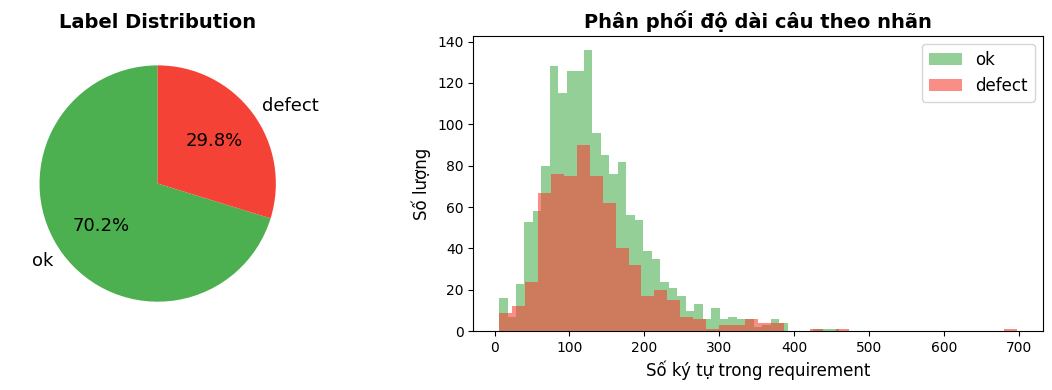


📊 Biểu đồ dataset đã lưu: dataset_overview.png


In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print('📁 Upload file datasetRE.csv:')
uploaded = files.upload()
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)
print(f'\n✅ Đã tải: {filename}')
print(f'   Tổng số mẫu  : {len(df)}')
print(f'   Cột          : {df.columns.tolist()}')
print(f'\nPhân phối nhãn:')
print(df['defect'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

label_order = ['ok', 'defect']
counts = df['defect'].value_counts().reindex(label_order, fill_value=0)
colors = ['#4CAF50', '#F44336']
axes[0].pie(counts.values, labels=counts.index,
            autopct='%1.1f%%', colors=colors,
            startangle=90, textprops={'fontsize':13})
axes[0].set_title('Label Distribution', fontsize=14, fontweight='bold')

df['length'] = df['requirement'].str.len()
for label, color in zip(label_order, colors):
    subset = df[df['defect'] == label]['length']
    axes[1].hist(subset, bins=40, alpha=0.6, label=label, color=color)
axes[1].set_xlabel('Số ký tự trong requirement', fontsize=12)
axes[1].set_ylabel('Số lượng', fontsize=12)
axes[1].set_title('Phân phối độ dài câu theo nhãn', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=12)

plt.tight_layout()
plt.savefig('dataset_overview.png', dpi=120, bbox_inches='tight')
plt.show()
print('\n📊 Biểu đồ dataset đã lưu: dataset_overview.png')


## 3. Stratified Dataset Partitioning
Partitions data into stratified Train (80%, 1,749 samples), Validation (10%, 219 samples), and Test (10%, 219 samples) subsets under configurable random seeds.

In [ ]:
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42
print(f'🎲 Đang sử dụng RANDOM_SEED = {RANDOM_SEED}')

df_trainval, df_test = train_test_split(
    df, test_size=0.10, random_state=RANDOM_SEED, stratify=df['defect']
)

df_train, df_val = train_test_split(
    df_trainval, test_size=0.1111, random_state=RANDOM_SEED, stratify=df_trainval['defect']
)

df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

print('📊 Kết quả split:')
print(f'   Train : {len(df_train):4d} mẫu  | ok={sum(df_train["defect"]=="ok")} | defect={sum(df_train["defect"]=="defect")}')
print(f'   Val   : {len(df_val):4d} mẫu  | ok={sum(df_val["defect"]=="ok")} | defect={sum(df_val["defect"]=="defect")}')
print(f'   Test  : {len(df_test):4d} mẫu  | ok={sum(df_test["defect"]=="ok")} | defect={sum(df_test["defect"]=="defect")}')
print(f'   Total : {len(df_train)+len(df_val)+len(df_test):4d} mẫu')


📊 Kết quả split:
   Train : 1749 mẫu  | ok=1228 | defect=521
   Val   :  219 mẫu  | ok=154 | defect=65
   Test  :  219 mẫu  | ok=154 | defect=65
   Total : 2187 mẫu


## 4. Prompt Engineering and Supervised Fine-Tuning Format
Constructs ChatML instruction prompts pairing requirements with target supervisory labels (`ok` or `defect`).

In [ ]:
import re
from typing import Optional

VALID_LABELS  = {"ok", "defect"}
MAX_REQ_CHARS = 800

SYSTEM_PROMPT = """You are an expert SRS (Software Requirements Specification) analyst.
Your task is to classify whether a given requirement contains a defect (ambiguity, vagueness, or incompleteness).
Respond with ONLY one word: either 'ok' or 'defect'. No explanation."""

def clean_requirement(text: str) -> str:
    """Chuẩn hóa whitespace và truncate nếu quá dài."""
    text = re.sub(r'\s+', ' ', str(text)).strip()
    if len(text) > MAX_REQ_CHARS:
        print(f"⚠️  Requirement bị truncate: {len(text)} → {MAX_REQ_CHARS} ký tự")
        text = text[:MAX_REQ_CHARS] + "..."
    return text

def build_prompt(requirement: str, label: str = None) -> list:
    """
    Tạo prompt theo Qwen2.5 chat format.
    - Training: có label (answer)
    - Inference: không có label
    """
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user",   "content": f"Requirement: {clean_requirement(requirement)}"}
    ]
    if label is not None:
        messages.append({"role": "assistant", "content": label})
    return messages

sample_req = df_train.iloc[0]['requirement']
sample_lbl = df_train.iloc[0]['defect']
print('📝 Ví dụ prompt (training):')
print(f'   Requirement : {sample_req[:80]}...')
print(f'   Label       : {sample_lbl}')
print()
for msg in build_prompt(sample_req, sample_lbl):
    print(f'[{msg["role"].upper()}] {msg["content"][:100]}')


📝 Ví dụ prompt (training):
   Requirement : Special attention must be paid to the following:...
   Label       : ok

[SYSTEM] You are an expert SRS (Software Requirements Specification) analyst.
Your task is to classify whethe
[USER] Requirement: Special attention must be paid to the following:
[ASSISTANT] ok


## 5. Model Loading with 4-bit QLoRA Configuration
Loads `Qwen/Qwen2.5-3B-Instruct` in NF4 4-bit quantization with LoRA adapters targetting all linear projection layers ($r=16, \alpha=32$).

In [ ]:
import torch
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig
)
from peft import LoraConfig, get_peft_model, TaskType, prepare_model_for_kbit_training

assert torch.cuda.is_available(), '❌ Không tìm thấy GPU! Hãy chọn T4 trong Runtime.'
vram_total = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f'🖥️  GPU  : {torch.cuda.get_device_name(0)}')
print(f'💾 VRAM : {vram_total:.1f} GB')

MODEL_ID = 'Qwen/Qwen2.5-3B-Instruct'

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

print(f'\n📥 Đang tải model: {MODEL_ID}')
print('⏳ Lần đầu tải ~6GB, 2-4 phút...\n')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, padding_side='right')

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map='auto',
    torch_dtype=torch.float16,
)

model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=[
        'q_proj', 'k_proj', 'v_proj', 'o_proj',
        'gate_proj', 'up_proj', 'down_proj'
    ],
    lora_dropout=0.05,
    bias='none',
    task_type=TaskType.CAUSAL_LM,
)

model = get_peft_model(model, lora_config)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
vram_used = torch.cuda.memory_allocated() / 1e9

print('✅ Model đã sẵn sàng!')
print(f'   Trainable params : {trainable:,} ({100*trainable/total:.2f}%)')
print(f'   Total params     : {total:,}')
print(f'   VRAM đang dùng   : {vram_used:.2f} GB / {vram_total:.1f} GB')


🖥️  GPU  : Tesla T4
💾 VRAM : 15.6 GB

📥 Đang tải model: Qwen/Qwen2.5-3B-Instruct
⏳ Lần đầu tải ~6GB, 2-4 phút...



config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

✅ Model đã sẵn sàng!
   Trainable params : 29,933,568 (1.73%)
   Total params     : 1,728,606,208
   VRAM đang dùng   : 2.81 GB / 15.6 GB


## 6. Dataset Tokenization and Supervised Loss Masking
Tokenizes input sequences and masks prompt tokens with label value `-100` so cross-entropy loss is computed exclusively on the target classification token.

In [ ]:
from datasets import Dataset

MAX_LENGTH = 256

def tokenize_sample(example):
    """Tokenize một sample và mask phần prompt đầu vào để không tính loss"""
    messages = build_prompt(example['requirement'], example['defect'])

    full_text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )

    prompt_messages = messages[:-1]
    prompt_text = tokenizer.apply_chat_template(
        prompt_messages,
        tokenize=False,
        add_generation_prompt=True
    )

    tokenized_full = tokenizer(
        full_text,
        max_length=MAX_LENGTH,
        padding='max_length',
        truncation=True,
        return_tensors=None
    )

    tokenized_prompt = tokenizer(
        prompt_text,
        max_length=MAX_LENGTH,
        truncation=True,
        return_tensors=None
    )

    prompt_len = len(tokenized_prompt['input_ids'])

    labels = tokenized_full['input_ids'].copy()

    for i in range(min(prompt_len, MAX_LENGTH)):
        labels[i] = -100

    for i in range(len(labels)):
        if tokenized_full['input_ids'][i] == tokenizer.pad_token_id:
            labels[i] = -100

    tokenized_full['labels'] = labels
    return tokenized_full

print('🔄 Đang tokenize dataset với cơ chế Masking Prompt...')

hf_train = Dataset.from_pandas(df_train[['requirement','defect']])
hf_val   = Dataset.from_pandas(df_val[['requirement','defect']])

hf_train = hf_train.map(tokenize_sample, batched=False, desc='Tokenizing train')
hf_val   = hf_val.map(tokenize_sample,   batched=False, desc='Tokenizing val')

keep_cols = ['input_ids', 'attention_mask', 'labels']
hf_train = hf_train.select_columns(keep_cols)
hf_val   = hf_val.select_columns(keep_cols)

print(f'\n✅ Tokenize hoàn tất!')
print(f'   Mô hình sẽ chỉ tập trung học 1 token duy nhất (ok/defect), phần prompt bị mask (-100).')


🔄 Đang tokenize dataset với cơ chế Masking Prompt...


Tokenizing train:   0%|          | 0/1749 [00:00<?, ? examples/s]

Tokenizing val:   0%|          | 0/219 [00:00<?, ? examples/s]


✅ Tokenize hoàn tất!
   Mô hình sẽ chỉ tập trung học 1 token duy nhất (ok/defect), phần prompt bị mask (-100).


## 7. Supervised Fine-Tuning Execution
Executes SFTTrainer with cosine learning rate scheduling, mixed precision (FP16/BF16), and evaluation-loss checkpointing.

In [ ]:
from transformers import TrainingArguments, DataCollatorForSeq2Seq, Trainer
import json

EPOCHS        = 4
BATCH_SIZE    = 4
GRAD_ACCUM    = 4
LR            = 2e-4
WARMUP_RATIO  = 0.05
OUTPUT_DIR    = f'./srs_llm_finetune_seed_{RANDOM_SEED}'

training_args = TrainingArguments(
    seed=RANDOM_SEED,
    data_seed=RANDOM_SEED,
    output_dir=OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR,
    warmup_ratio=WARMUP_RATIO,
    lr_scheduler_type='cosine',
    fp16=True,
    optim='paged_adamw_8bit',
    logging_steps=5,
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    greater_is_better=False,
    report_to='none',
    dataloader_num_workers=0,
    remove_unused_columns=False,
)

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    pad_to_multiple_of=8,
    label_pad_token_id=-100
)

from transformers import TrainerCallback

class HistoryCallback(TrainerCallback):
    def __init__(self):
        self.train_loss_steps = []
        self.val_loss_epochs  = []
        self.lr_history       = []

    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs:
            if 'loss' in logs:
                self.train_loss_steps.append((state.global_step, logs['loss']))
            if 'eval_loss' in logs:
                self.val_loss_epochs.append((state.epoch, logs['eval_loss']))
            if 'learning_rate' in logs:
                self.lr_history.append((state.global_step, logs['learning_rate']))

history_cb = HistoryCallback()

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=hf_train,
    eval_dataset=hf_val,
    data_collator=data_collator,
    callbacks=[history_cb],
)

print('🚀 Bắt đầu huấn luyện mô hình...')
print(f'   Train samples  : {len(hf_train)}')
print(f'   Epochs         : {EPOCHS} | Batch={BATCH_SIZE} | Grad Accum={GRAD_ACCUM} '
      f'(effective batch={BATCH_SIZE*GRAD_ACCUM})')
print()

train_result = trainer.train()

print('\n✅ Huấn luyện hoàn tất!')
print(f'   Training loss cuối : {train_result.training_loss:.4f}')
if getattr(trainer.state, 'best_model_checkpoint', None):
    print(f'🏆 Epoch/checkpoint tốt nhất: {trainer.state.best_model_checkpoint} '
          f'(eval_loss = {trainer.state.best_metric:.4f})')

with open('training_history.json', 'w') as f:
    json.dump({
        'train_loss_steps': history_cb.train_loss_steps,
        'val_loss_epochs':  history_cb.val_loss_epochs,
        'lr_history':       history_cb.lr_history
    }, f)


[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


🚀 Bắt đầu huấn luyện mô hình...
   Train samples  : 1749
   Epochs         : 4 | Batch=4 | Grad Accum=4 (effective batch=16)



Epoch,Training Loss,Validation Loss
1,0.151172,0.182683
2,0.101972,0.131348
3,0.049255,0.086105
4,0.015181,0.106671



✅ Huấn luyện hoàn tất!
   Training loss cuối : 0.1098
🏆 Epoch/checkpoint tốt nhất: ./srs_llm_finetune/checkpoint-330 (eval_loss = 0.0861)


## 8. Training Dynamics and Convergence Visualization
Plots training and validation loss trajectories across optimization steps to verify convergence and monitor potential overfitting.

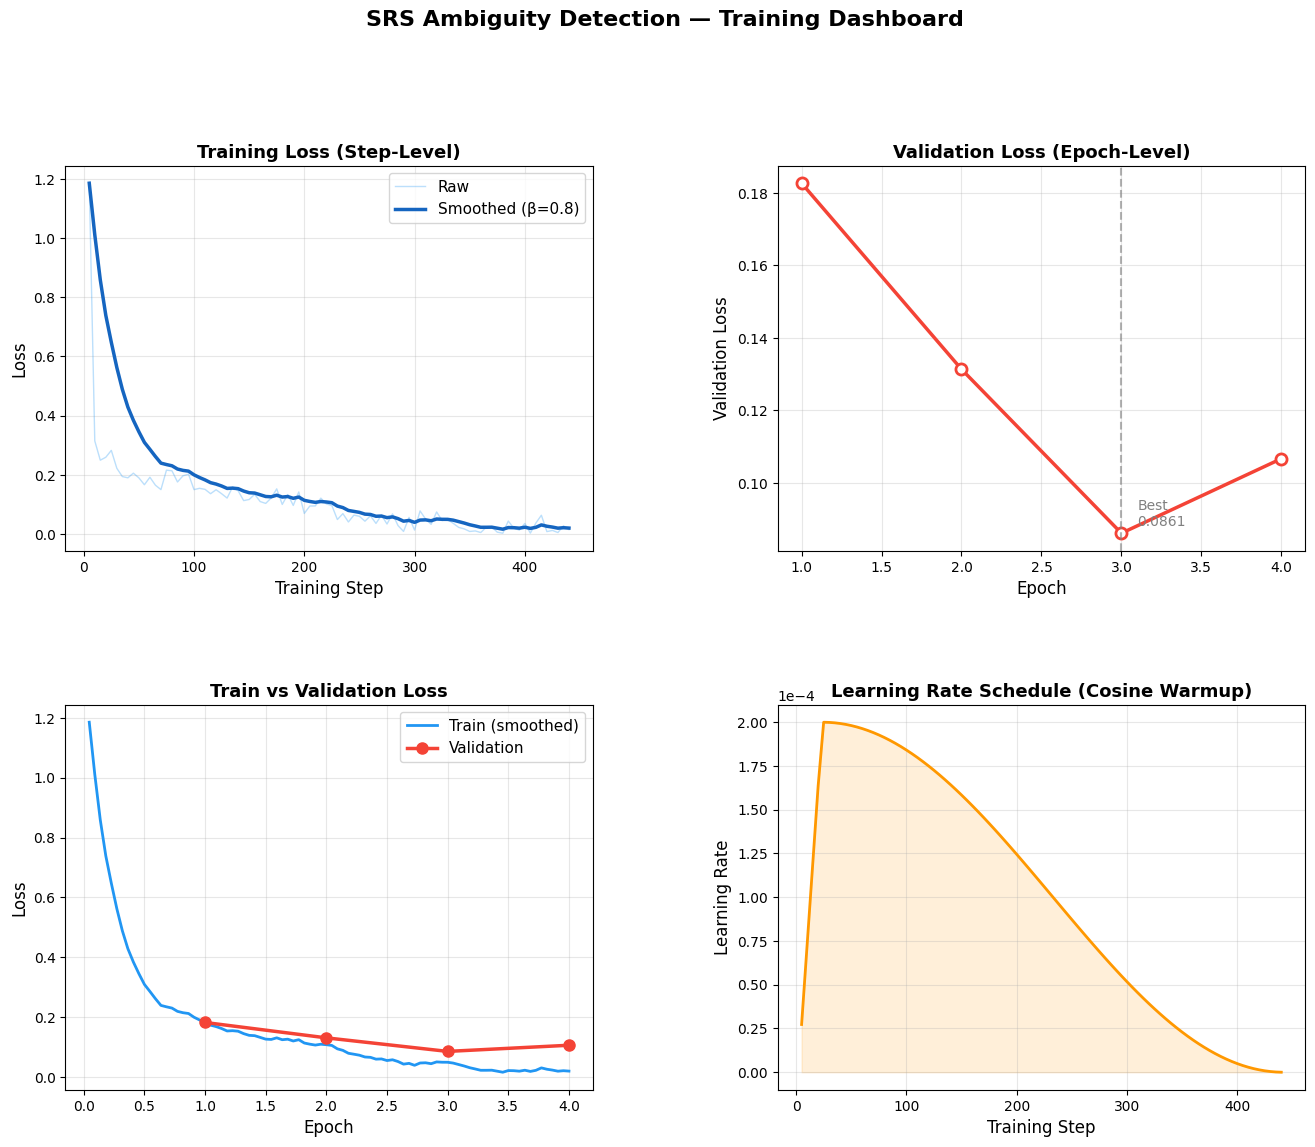

📊 Dashboard lưu tại: training_dashboard.png

📋 Training Summary:
   Initial train loss : 1.1850
   Final train loss   : 0.0152
   Best val loss      : 0.0861  (epoch 3.0)
   Final val loss     : 0.1067


In [ ]:
import json
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

with open('training_history.json') as f:
    hist = json.load(f)

train_steps  = [x[0] for x in hist['train_loss_steps']]
train_losses = [x[1] for x in hist['train_loss_steps']]
val_epochs   = [x[0] for x in hist['val_loss_epochs']]
val_losses   = [x[1] for x in hist['val_loss_epochs']]
lr_steps     = [x[0] for x in hist['lr_history']]
lr_values    = [x[1] for x in hist['lr_history']]

def smooth(values, weight=0.8):
    smoothed = []
    last = values[0]
    for v in values:
        last = last * weight + v * (1 - weight)
        smoothed.append(last)
    return smoothed

train_smooth = smooth(train_losses)

fig = plt.figure(figsize=(16, 12))
gs  = gridspec.GridSpec(2, 2, hspace=0.4, wspace=0.35)

COLORS = {'train':'#2196F3', 'val':'#F44336', 'lr':'#FF9800', 'smooth':'#1565C0'}

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(train_steps, train_losses, alpha=0.3, color=COLORS['train'], linewidth=1, label='Raw')
ax1.plot(train_steps, train_smooth, color=COLORS['smooth'], linewidth=2.5, label='Smoothed (β=0.8)')
ax1.set_xlabel('Training Step', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.set_title('Training Loss (Step-Level)', fontsize=13, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(val_epochs, val_losses, 'o-', color=COLORS['val'],
         linewidth=2.5, markersize=8, markerfacecolor='white', markeredgewidth=2)
best_idx = int(np.argmin(val_losses))
ax2.axvline(x=val_epochs[best_idx], color='gray', linestyle='--', alpha=0.6)
ax2.annotate(f'Best\n{val_losses[best_idx]:.4f}',
             xy=(val_epochs[best_idx], val_losses[best_idx]),
             xytext=(val_epochs[best_idx]+0.1, val_losses[best_idx]+0.002),
             fontsize=10, color='gray')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Validation Loss', fontsize=12)
ax2.set_title('Validation Loss (Epoch-Level)', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
steps_per_epoch = max(train_steps) / len(val_epochs) if val_epochs else 1
train_epochs_x  = [s / steps_per_epoch for s in train_steps]
ax3.plot(train_epochs_x, train_smooth, color=COLORS['train'], linewidth=2, label='Train (smoothed)')
ax3.plot(val_epochs, val_losses, 'o-', color=COLORS['val'],
         linewidth=2.5, markersize=8, label='Validation')
ax3.set_xlabel('Epoch', fontsize=12)
ax3.set_ylabel('Loss', fontsize=12)
ax3.set_title('Train vs Validation Loss', fontsize=13, fontweight='bold')
ax3.legend(fontsize=11)
ax3.grid(True, alpha=0.3)

if len(val_losses) >= 3:
    last3_val = val_losses[-3:]
    if last3_val[-1] > last3_val[0]:
        ax3.text(0.98, 0.95, '⚠️ Possible overfitting',
                 transform=ax3.transAxes, ha='right', va='top',
                 fontsize=10, color='red',
                 bbox=dict(boxstyle='round', facecolor='#FFEBEE', alpha=0.8))

ax4 = fig.add_subplot(gs[1, 1])
if lr_steps:
    ax4.plot(lr_steps, lr_values, color=COLORS['lr'], linewidth=2)
    ax4.fill_between(lr_steps, lr_values, alpha=0.15, color=COLORS['lr'])
ax4.set_xlabel('Training Step', fontsize=12)
ax4.set_ylabel('Learning Rate', fontsize=12)
ax4.set_title('Learning Rate Schedule (Cosine Warmup)', fontsize=13, fontweight='bold')
ax4.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax4.grid(True, alpha=0.3)

fig.suptitle('SRS Ambiguity Detection — Training Dashboard', fontsize=16, fontweight='bold', y=1.01)
plt.savefig('training_dashboard.png', dpi=130, bbox_inches='tight')
plt.show()
print('📊 Dashboard lưu tại: training_dashboard.png')

print('\n📋 Training Summary:')
print(f'   Initial train loss : {train_losses[0]:.4f}')
print(f'   Final train loss   : {train_losses[-1]:.4f}')
print(f'   Best val loss      : {min(val_losses):.4f}  (epoch {val_epochs[best_idx]})')
print(f'   Final val loss     : {val_losses[-1]:.4f}')


## 9. Hold-Out Test Evaluation and Probability Logits Extraction
Performs forward inference on the hold-out test set to extract candidate logits and calibrated continuous probabilities $P(\text{defect})$.

In [ ]:
import torch
from tqdm import tqdm

model.eval()
tok = tokenizer

id_ok = tok.encode('ok', add_special_tokens=False)[0]
id_defect = tok.encode('defect', add_special_tokens=False)[0]
print(f'🎯 Target Token IDs: ok={id_ok}, defect={id_defect}')

def predict(requirement: str) -> tuple[str, float]:
    """
    Dự đoán nhãn và trích xuất xác suất liên tục P(defect).
    Returns:
        pred_label: 'ok' hoặc 'defect'
        p_defect: float liên tục trong khoảng [0.0, 1.0]
    """
    messages = build_prompt(requirement)
    text_input = tok.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = tok(
        text_input,
        return_tensors='pt',
        truncation=True,
        max_length=256
    ).to(model.device)

    with torch.no_grad():
        outputs = model(**inputs)
        next_token_logits = outputs.logits[0, -1, :]
        logits_pair = torch.tensor([next_token_logits[id_ok], next_token_logits[id_defect]], device=model.device)
        probs = torch.softmax(logits_pair, dim=-1)

        p_defect = probs[1].item()
        pred_label = 'defect' if p_defect >= 0.5 else 'ok'
        return pred_label, p_defect

print(f'🔮 Bắt đầu Inference trên {len(df_test)} test samples (Seed: {RANDOM_SEED})...')
y_true = []
y_pred = []
y_scores = []

for idx, row in tqdm(df_test.iterrows(), total=len(df_test), desc='GPU Inference'):
    req = str(row['requirement'])
    true_label = str(row['defect']).strip().lower()
    pred_label, p_defect = predict(req)

    y_true.append(true_label)
    y_pred.append(pred_label)
    y_scores.append(p_defect)

df_test['predicted'] = y_pred
df_test['p_defect']  = y_scores
df_test['correct']   = df_test['defect'] == df_test['predicted']

acc_check = sum(df_test['correct']) / len(df_test)
print(f'\n✅ Quy trình Inference hoàn tất!')
print(f'   Accuracy quick check trên Test Set: {acc_check:.4f} ({acc_check*100:.2f}%)')


🔮 Back-testing trên 219 test samples...


Predicting: 100%|██████████| 219/219 [01:38<00:00,  2.23it/s]


✅ Inference xong!
   Accuracy quick check: 0.8539


## 10. Quantitative Performance Metrics & Calibration
Evaluates Accuracy, Balanced Accuracy, Precision, Recall, Class-specific F1, Macro F1, MCC, Standard ROC-AUC, and PR-AUC.

         EVALUATION REPORT — TEST SET
  Accuracy         : 0.8539  (85.39%)
  F1 (macro)       : 0.8182
  F1 (weighted)    : 0.8509
  MCC              : 0.6397  (range: -1 ~ 1)
  ROC-AUC          : 0.8072

  Class: defect
    Precision      : 0.7895
    Recall         : 0.6923
    F1-score       : 0.7377

  Class: ok
    Precision      : 0.8765
    Recall         : 0.9221
    F1-score       : 0.8987

Confusion Matrix (rows=actual, cols=predicted):
              ok    defect
  actual ok  :  142      12
  actual def :   20      45


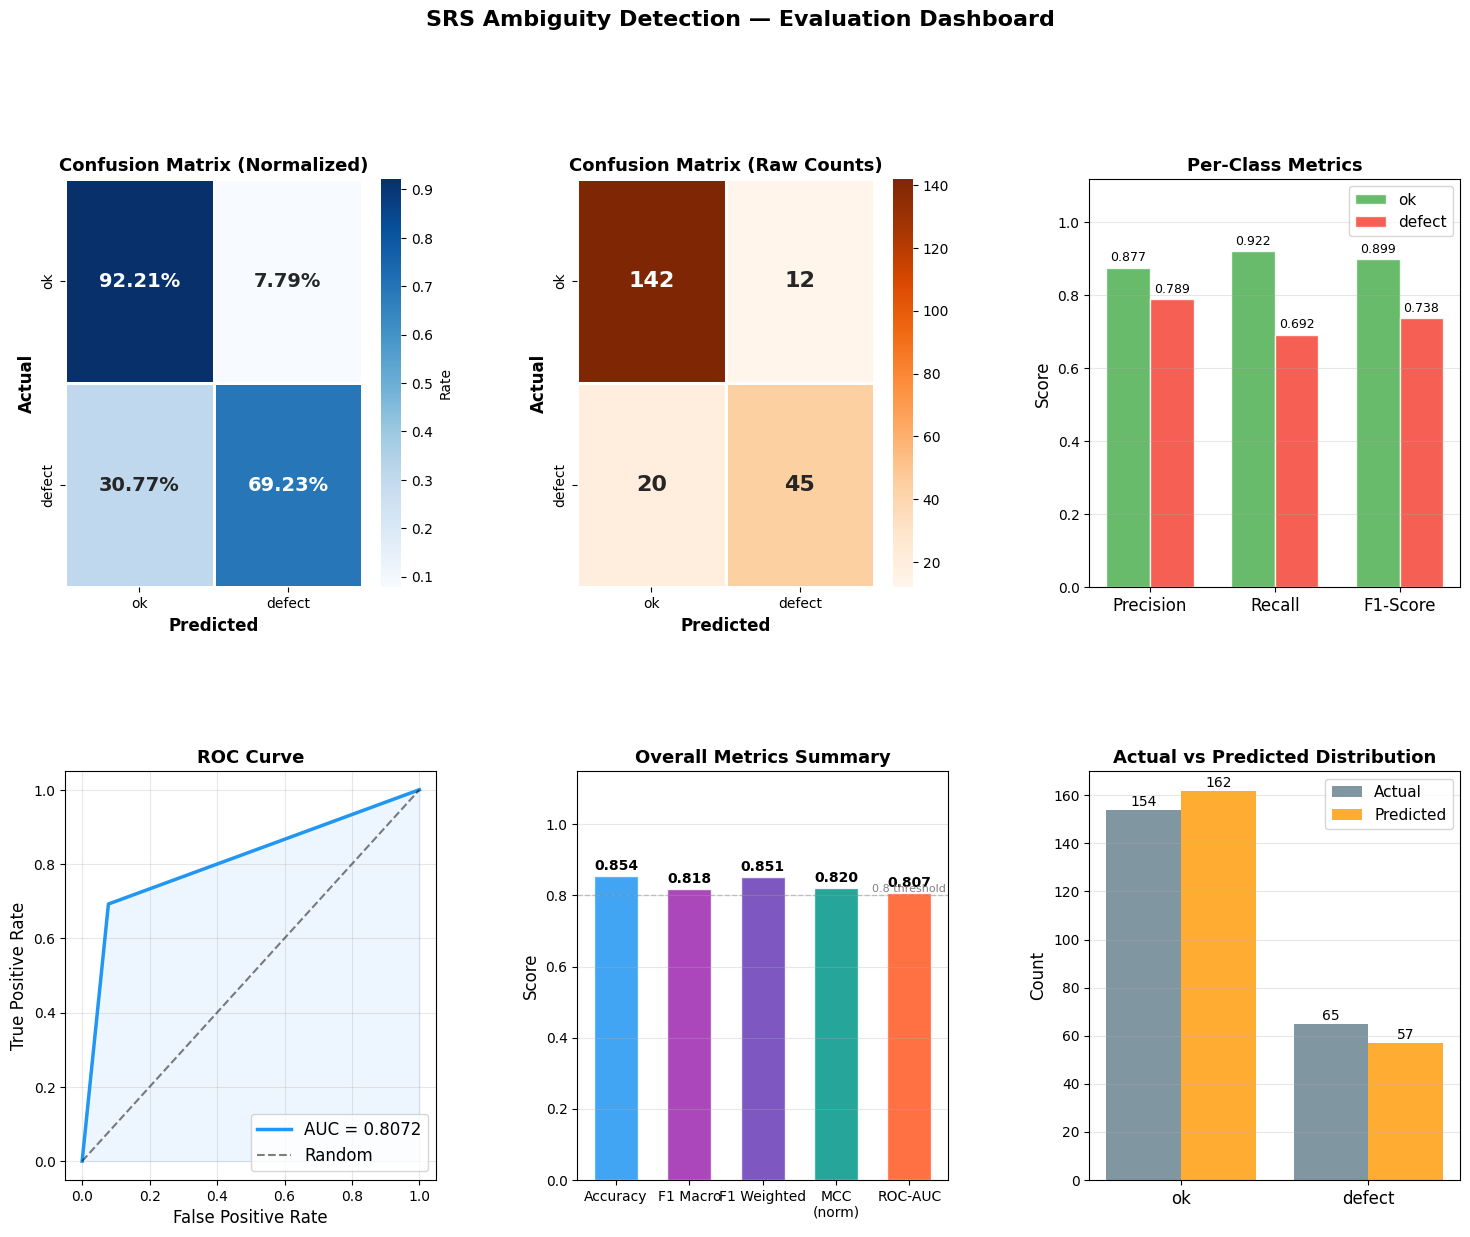

📊 Evaluation dashboard lưu tại: evaluation_dashboard.png


In [ ]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve, precision_recall_curve, auc as calc_auc, matthews_corrcoef
)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
import pandas as pd

label2int = {'ok': 0, 'defect': 1}
y_true_bin = [label2int[l] for l in y_true]
y_pred_bin = [label2int[l] for l in y_pred]
y_score    = y_scores

acc       = accuracy_score(y_true_bin, y_pred_bin)
bacc      = balanced_accuracy_score(y_true_bin, y_pred_bin)
prec_d    = precision_score(y_true_bin, y_pred_bin, pos_label=1)
rec_d     = recall_score(y_true_bin,    y_pred_bin, pos_label=1)
f1_d      = f1_score(y_true_bin,        y_pred_bin, pos_label=1)
prec_ok   = precision_score(y_true_bin, y_pred_bin, pos_label=0)
rec_ok    = recall_score(y_true_bin,    y_pred_bin, pos_label=0)
f1_ok     = f1_score(y_true_bin,        y_pred_bin, pos_label=0)
f1_macro  = f1_score(y_true_bin,        y_pred_bin, average='macro')
f1_weight = f1_score(y_true_bin,        y_pred_bin, average='weighted')
mcc       = matthews_corrcoef(y_true_bin, y_pred_bin)
cm        = confusion_matrix(y_true_bin, y_pred_bin)

try:
    roc_auc = roc_auc_score(y_true_bin, y_score)
    fpr, tpr, _ = roc_curve(y_true_bin, y_score)
except Exception as e:
    roc_auc = float('nan')

try:
    pr_prec, pr_rec, _ = precision_recall_curve(y_true_bin, y_score)
    pr_auc = calc_auc(pr_rec, pr_prec)
except Exception as e:
    pr_auc = float('nan')

print('=' * 58)
print('   EVALUATION REPORT — TEST SET (Seed: {RANDOM_SEED})')
print('=' * 58)
print(f'  Accuracy             : {acc:.4f}  ({acc*100:.2f}%)')
print(f'  Balanced Acc (BAcc)  : {bacc:.4f}')
print(f'  F1 (macro)           : {f1_macro:.4f}')
print(f'  F1 (weighted)        : {f1_weight:.4f}')
print(f'  MCC                  : {mcc:.4f}  (range: -1 ~ 1)')
print(f'  Standard ROC-AUC     : {roc_auc:.4f}')
print(f'  PR-AUC               : {pr_auc:.4f}')
print()
print('  Class: defect (Ambiguous)')
print(f'    Precision          : {prec_d:.4f}')
print(f'    Recall             : {rec_d:.4f}')
print(f'    F1-score           : {f1_d:.4f}')
print()
print('  Class: ok (Unambiguous)')
print(f'    Precision          : {prec_ok:.4f}')
print(f'    Recall             : {rec_ok:.4f}')
print(f'    F1-score           : {f1_ok:.4f}')
print('=' * 58)

fig = plt.figure(figsize=(18, 13))
gs  = gridspec.GridSpec(2, 3, hspace=0.45, wspace=0.38)

ax1 = fig.add_subplot(gs[0, 0])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=['ok','defect'], yticklabels=['ok','defect'],
            ax=ax1, linewidths=1, annot_kws={'size': 14, 'weight': 'bold'})
ax1.set_xlabel('Predicted', fontsize=12, fontweight='bold')
ax1.set_ylabel('Actual', fontsize=12, fontweight='bold')
ax1.set_title('Confusion Matrix (Normalized)', fontsize=13, fontweight='bold')

ax2 = fig.add_subplot(gs[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['ok','defect'], yticklabels=['ok','defect'],
            ax=ax2, linewidths=1, annot_kws={'size': 16, 'weight': 'bold'})
ax2.set_xlabel('Predicted', fontsize=12, fontweight='bold')
ax2.set_ylabel('Actual', fontsize=12, fontweight='bold')
ax2.set_title('Confusion Matrix (Raw Counts)', fontsize=13, fontweight='bold')

ax3 = fig.add_subplot(gs[0, 2])
metrics_names = ['Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics_names))
w = 0.35
ax3.bar(x - w/2, [prec_ok, rec_ok, f1_ok], w, label='ok', color='#4CAF50', alpha=0.85)
ax3.bar(x + w/2, [prec_d,  rec_d,  f1_d],  w, label='defect', color='#F44336', alpha=0.85)
ax3.set_xticks(x)
ax3.set_xticklabels(metrics_names, fontsize=12)
ax3.set_ylim(0, 1.15)
ax3.set_title('Per-Class Metrics', fontsize=13, fontweight='bold')
ax3.legend(fontsize=11)
ax3.grid(axis='y', alpha=0.3)

ax4 = fig.add_subplot(gs[1, 0])
if not np.isnan(roc_auc):
    ax4.plot(fpr, tpr, color='#2196F3', lw=2.5, label=f'ROC-AUC = {roc_auc:.4f}')
ax4.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5, label='Random')
ax4.set_xlabel('False Positive Rate', fontsize=12)
ax4.set_ylabel('True Positive Rate', fontsize=12)
ax4.set_title('Standard ROC Curve', fontsize=13, fontweight='bold')
ax4.legend(fontsize=12, loc='lower right')
ax4.grid(True, alpha=0.3)

ax5 = fig.add_subplot(gs[1, 1])
summary_names = ['Accuracy', 'BAcc', 'F1 Macro', 'MCC (norm)', 'ROC-AUC']
mcc_norm = (mcc + 1) / 2
summary_scores = [acc, bacc, f1_macro, mcc_norm, roc_auc if not np.isnan(roc_auc) else 0]
bars = ax5.bar(summary_names, summary_scores, color=['#2196F3','#00BCD4','#9C27B0','#009688','#FF5722'], alpha=0.85)
for bar, score in zip(bars, summary_scores):
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{score:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax5.set_ylim(0, 1.15)
ax5.set_title('Overall Metrics Summary', fontsize=13, fontweight='bold')
ax5.grid(axis='y', alpha=0.3)

ax6 = fig.add_subplot(gs[1, 2])
if not np.isnan(pr_auc):
    ax6.plot(pr_rec, pr_prec, color='#E91E63', lw=2.5, label=f'PR-AUC = {pr_auc:.4f}')
ax6.set_xlabel('Recall', fontsize=12)
ax6.set_ylabel('Precision', fontsize=12)
ax6.set_title('Precision-Recall Curve', fontsize=13, fontweight='bold')
ax6.legend(fontsize=12, loc='lower left')
ax6.grid(True, alpha=0.3)

fig.suptitle('Qwen2.5-3B-Instruct (Fine-Tuned) — Evaluation Dashboard (Seed: {RANDOM_SEED})', fontsize=16, fontweight='bold', y=1.01)
plt.savefig(f'evaluation_dashboard_seed_{RANDOM_SEED}.png', dpi=130, bbox_inches='tight')
plt.show()
print(f'📊 Dashboard đã lưu: evaluation_dashboard_seed_{RANDOM_SEED}.png')


## 11. Qualitative Error Inspection
Performs automated error isolation on False Positives and False Negatives to evaluate residual ambiguity patterns.

In [ ]:
import textwrap

errors = df_test[~df_test['correct']].copy()
fn = errors[(errors['defect'] == 'defect') & (errors['predicted'] == 'ok')]
fp = errors[(errors['defect'] == 'ok')     & (errors['predicted'] == 'defect')]

print('=' * 60)
print('         ERROR ANALYSIS')
print('=' * 60)
print(f'Tổng lỗi        : {len(errors)} / {len(df_test)} ({len(errors)/len(df_test)*100:.1f}%)')
print(f'False Negatives : {len(fn)}  (defect bị bỏ sót → nguy hiểm hơn)')
print(f'False Positives : {len(fp)}  (ok bị đánh nhầm là defect)')

print('\n--- 5 False Negatives (defect nhưng predict là ok) ---')
for i, (_, row) in enumerate(fn.head(5).iterrows()):
    print(f'\n[FN {i+1}] {textwrap.fill(row["requirement"], 70)}')

print('\n--- 5 False Positives (ok nhưng predict là defect) ---')
for i, (_, row) in enumerate(fp.head(5).iterrows()):
    print(f'\n[FP {i+1}] {textwrap.fill(row["requirement"], 70)}')

errors[['requirement','defect','predicted']].to_csv('error_analysis.csv', index=False)
print('\n💾 Lưu errors ra: error_analysis.csv')


         ERROR ANALYSIS
Tổng lỗi        : 32 / 219 (14.6%)
False Negatives : 20  (defect bị bỏ sót → nguy hiểm hơn)
False Positives : 12  (ok bị đánh nhầm là defect)

--- 5 False Negatives (defect nhưng predict là ok) ---

[FN 1] The first antenna layout comes close to the performance requirements
of the KLH antenna structures.

[FN 2] If an object stops, which was detected earlier as moving and an
orientation angle could be determined, the orientation angle of the
object has to be compensated, as long as the object is standing, by
the movement of the ego vehicle (aim: determination of the potential
driving direction of the object in case it is moving again).

[FN 3] If possible, it should be suitable to be mounted on stadard radar
samples without additional special modification of the samples.

[FN 4] If output power is not longer reduced and detection of an object is
possible in the same system cycle the component has to set the signal
'' DTR_SensOut_Rdc equal 0?Â on bus object inte

## 12. Model Artifact Serialization & Multi-Seed Results Export
Saves trained LoRA adapter weights, configuration files, and evaluation metrics serialized with seed-specific identifiers.

In [ ]:
import json

metrics_data = {
    'model': 'llm_finetune',
    'seed': RANDOM_SEED,
    'accuracy': float(acc),
    'balanced_accuracy': float(bacc),
    'precision_defect': float(prec_d),
    'recall_defect': float(rec_d),
    'f1_defect': float(f1_d),
    'precision_ok': float(prec_ok),
    'recall_ok': float(rec_ok),
    'f1_ok': float(f1_ok),
    'f1_macro': float(f1_macro),
    'f1_weighted': float(f1_weight),
    'mcc': float(mcc),
    'roc_auc': float(roc_auc) if not np.isnan(roc_auc) else None,
    'pr_auc': float(pr_auc) if not np.isnan(pr_auc) else None,
    'confusion_matrix': cm.tolist(),
}

json_filename = f'metrics_llm_finetune_seed_{RANDOM_SEED}.json'
csv_filename  = f'predictions_llm_finetune_seed_{RANDOM_SEED}.csv'

with open(json_filename, 'w', encoding='utf-8') as f:
    json.dump(metrics_data, f, indent=2, ensure_ascii=False)

df_test.to_csv(csv_filename, index=False, encoding='utf-8')

print(f'💾 Đã lưu file kết quả:')
print(f'   - Metrics JSON : {json_filename}')
print(f'   - Predictions  : {csv_filename}')


✅ LoRA adapter lưu tại: ./srs_lora_adapter/

📁 Các file đã lưu:
   evaluation_metrics.json  — tất cả metrics
   test_predictions.csv     — prediction trên test set
   error_analysis.csv       — các sample bị dự đoán sai
   training_dashboard.png   — biểu đồ training
   evaluation_dashboard.png — biểu đồ evaluation

📥 Đang download kết quả...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Hoàn tất!


## 13. Qualitative Demonstration Routine
Interactive interface for verifying fine-tuned model inference on arbitrary requirement statements.

In [ ]:
TEST_CASES = [
    "The system shall handle multiple sessions quickly and provide adequate performance.",
    "All data should be validated before it is stored.",
    "The system shall respond to all API requests within 200 milliseconds under normal load.",
    "The login module shall authenticate users using SHA-256 hashed passwords stored in PostgreSQL.",
]

print('🧪 Demo Inference\n')
print('─' * 65)

for i, req in enumerate(TEST_CASES, 1):
    pred = predict(req)
    icon = '🔴' if pred == 'defect' else '✅'
    print(f'[{i}] {icon} {pred.upper()}')
    print(f'     {req[:75]}...' if len(req) > 75 else f'     {req}')
    print()


🧪 Demo Inference

─────────────────────────────────────────────────────────────────
[1] 🔴 DEFECT
     The system shall handle multiple sessions quickly and provide adequate perf...

[2] ✅ OK
     All data should be validated before it is stored.

[3] ✅ OK
     The system shall respond to all API requests within 200 milliseconds under ...

[4] ✅ OK
     The login module shall authenticate users using SHA-256 hashed passwords st...

